In [1]:
# ==============================================================================
# 1. SETUP & DATA LOADING
# ==============================================================================
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score
import warnings

warnings.filterwarnings("ignore")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Using Device: {device}")

# Paper Plot Styling
sns.set_context("paper", font_scale=1.2)
plt.rcParams.update({
    "font.family": "serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.3,
    "savefig.bbox": "tight",
})

UNIFIED_PATH = "./btp_3class_dataset"
IMG_SIZE, BATCH = 224, 32

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

loaders = {x: DataLoader(datasets.ImageFolder(f"{UNIFIED_PATH}/{x}", transform), 
                         batch_size=BATCH, shuffle=(x=='train')) for x in ['train', 'val', 'test']}

✅ Using Device: cuda


In [2]:
# ==============================================================================
# 2. DEFINE CUSTOM CNN ARCHITECTURE (BTP-Net)
# ==============================================================================
class CustomBTPNet(nn.Module):
    def __init__(self, num_classes=3):
        super(CustomBTPNet, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool = nn.MaxPool2d(2, 2)
        
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        
        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(256)
        
        self.fc1 = nn.Linear(256 * 14 * 14, 512)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.pool(F.relu(self.bn4(self.conv4(x))))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

model = CustomBTPNet(num_classes=3).to(device)

In [3]:
# ==============================================================================
# 3. TRAINING LOOP
# ==============================================================================
print("\n" + "="*50 + "\n🚀 TRAINING CUSTOM BTP-NET\n" + "="*50)
epochs = 10
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)
best_acc = 0.0
weights_path = "best_custom_btp_net_3class.pth"

for epoch in range(epochs):
    model.train()
    for imgs, labels in tqdm(loaders['train'], desc=f"Epoch {epoch+1}/{epochs}"):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(imgs), labels)
        loss.backward()
        optimizer.step()
    
    # Validation Checkpoint
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for imgs, labels in loaders['val']:
            out = model(imgs.to(device))
            preds.extend(torch.argmax(out, 1).cpu().numpy())
            targets.extend(labels.numpy())
    
    acc = accuracy_score(targets, preds)
    print(f"   Val Acc: {acc:.4f}")
    if acc > best_acc:
        best_acc = acc
        torch.save(model.state_dict(), weights_path)
        print(f"   ⭐ Saved best model!")

# Load the best weights for testing
print("\n📥 Loading best weights for Robustness Evaluation...")
model.load_state_dict(torch.load(weights_path))
model.eval()


🚀 TRAINING CUSTOM BTP-NET


Epoch 1/10: 100%|███████████████████████████████████████████████████████████████████████| 99/99 [03:10<00:00,  1.93s/it]


   Val Acc: 0.9570
   ⭐ Saved best model!


Epoch 2/10: 100%|███████████████████████████████████████████████████████████████████████| 99/99 [03:20<00:00,  2.03s/it]


   Val Acc: 0.9467


Epoch 3/10: 100%|███████████████████████████████████████████████████████████████████████| 99/99 [04:34<00:00,  2.78s/it]


... (12 outputs left out)

   Val Acc: 0.9630


Epoch 10/10: 100%|██████████████████████████████████████████████████████████████████████| 99/99 [04:13<00:00,  2.56s/it]


   Val Acc: 0.9778
   ⭐ Saved best model!

📥 Loading best weights for Robustness Evaluation...


CustomBTPNet(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv4): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc1): Linear(in_features=50176, out_features=512, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=512, out_features=3, bias=True)
)

In [5]:
# ==============================================================================
# 4. CLINICAL NOISE ROBUSTNESS EVALUATION (With CUDA Fixes)
# ==============================================================================
class ClinicalNoise:
    @staticmethod
    def apply_poisson(img, sigma):
        peak = 1.0 / (sigma + 1e-6)
        rate = torch.clamp(img * peak, min=0.0)
        return torch.poisson(rate) / peak

    @staticmethod
    def apply_speckle(img, sigma):
        return img + img * torch.randn_like(img) * sigma

    @staticmethod
    def apply_salt_pepper(img, sigma):
        noisy = img.clone()
        mask = torch.rand_like(img)
        noisy[mask < (sigma/2)] = -2.5
        noisy[mask > (1 - sigma/2)] = 2.5
        return noisy

    @staticmethod
    def apply_gaussian(img, sigma):
        return img + sigma * torch.randn_like(img)

noise_types = ["Poisson", "Speckle", "Salt&Pepper", "Gaussian"]
levels = [0.01, 0.05, 0.1, 0.2]
robustness_results = {nt: [] for nt in noise_types}

print("\n" + "="*50 + "\n🔬 RUNNING ROBUSTNESS EVALUATION\n" + "="*50)
for nt in noise_types:
    print(f"Evaluating {nt} noise...")
    for lvl in levels:
        test_preds, test_targets = [], []
        
        with torch.no_grad():
            for imgs, labels in loaders['test']:
                imgs = imgs.to(device)
                
                # Inject Noise
                if nt == "Poisson": noisy = ClinicalNoise.apply_poisson(imgs, lvl)
                elif nt == "Speckle": noisy = ClinicalNoise.apply_speckle(imgs, lvl)
                elif nt == "Salt&Pepper": noisy = ClinicalNoise.apply_salt_pepper(imgs, lvl)
                else: noisy = ClinicalNoise.apply_gaussian(imgs, lvl)
                
                test_targets.extend(labels.numpy())
                out = model(noisy)
                test_preds.extend(torch.argmax(out, dim=1).cpu().numpy())
        
        acc = accuracy_score(test_targets, test_preds)
        robustness_results[nt].append(acc)


🔬 RUNNING ROBUSTNESS EVALUATION
Evaluating Poisson noise...
Evaluating Speckle noise...
Evaluating Salt&Pepper noise...
Evaluating Gaussian noise...



📊 Generating Publication-Ready Plot...
✅ Done! Plot saved as 'Fig2_Custom_BTPNet_Robustness.pdf'


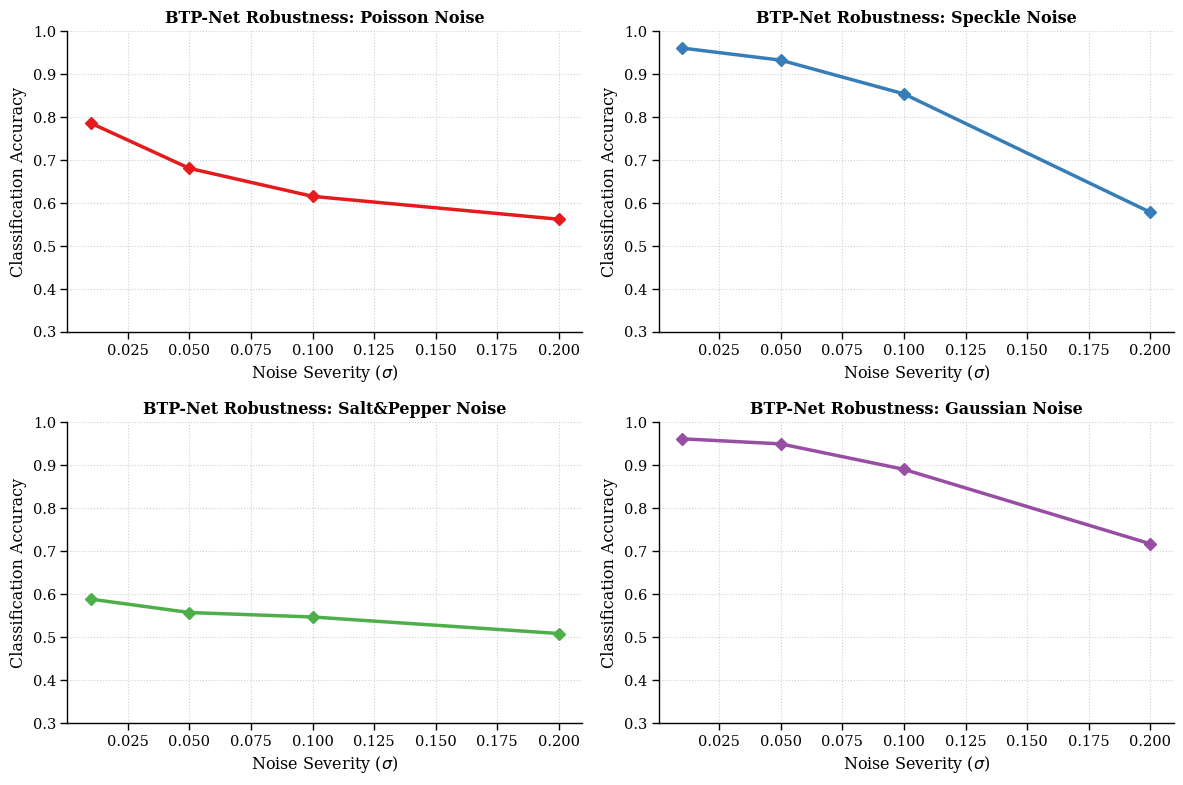

In [6]:
# ==============================================================================
# 5. PAPER PLOT: BTP-NET ROBUSTNESS
# ==============================================================================
print("\n📊 Generating Publication-Ready Plot...")
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
colors = sns.color_palette("Set1", 4)

for i, nt in enumerate(noise_types):
    ax = axes[i//2, i%2]
    ax.plot(levels, robustness_results[nt], marker='D', markersize=6, 
            linewidth=2.5, color=colors[i], label=f"BTP-Net ({nt})")
    
    ax.set_title(f"BTP-Net Robustness: {nt} Noise", fontweight='bold')
    ax.set_xlabel("Noise Severity ($\sigma$)")
    ax.set_ylabel("Classification Accuracy")
    ax.set_ylim([0.3, 1.0]) # Set Y-axis so 0.33 (random guessing) is visible at the bottom
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("Fig2_Custom_BTPNet_Robustness.pdf", format='pdf', dpi=300)
plt.savefig("Fig2_Custom_BTPNet_Robustness.png", dpi=300)

print("✅ Done! Plot saved as 'Fig2_Custom_BTPNet_Robustness.pdf'")
plt.show()